# WESAD 기준 실험 따라가기

교수자·조교 제공 시작 코드의 데이터 규칙, 특징, 참가자 분할, LR 네 조건과 결과 파일을 확인합니다. 먼저 README의 전체 실행 명령으로 실제 WESAD 결과를 생성하세요. 이 노트북의 기본 실행은 저장된 실제 특징을 읽고 같은 평가 모듈을 다시 실행합니다.

Advanced Model 개발과 RQ1–RQ4의 연구 설계·실험·해석은 학생이 수행합니다. 수업용 통계 특징 기준이며 기존 논문 실험의 재현은 아닙니다.

In [1]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'wesad_starter').is_dir()), None)
if project_root is None:
    raise RuntimeError('프로젝트 폴더 또는 notebooks 폴더에서 실행하세요.')
sys.path.insert(0, str(project_root))
results_dir = Path(os.environ.get('WESAD_RESULTS', str(project_root / 'results' / 'baseline'))).expanduser()
if not results_dir.is_absolute():
    results_dir = project_root / results_dir
data_root = Path(os.environ.get('WESAD_ROOT', str(Path.home() / 'ResearchDatasets' / 'WESAD'))).expanduser()
print('결과 경로:', results_dir)
print('선택적 원신호 경로:', data_root)


결과 경로: /Users/bhyung/GitHub/AffectiveComputing/results/baseline
선택적 원신호 경로: /Users/bhyung/ResearchDatasets/WESAD


## 1. 구간과 원래 조건 확인

기록 시작점부터 60초 비중첩 격자를 만듭니다. 원래 조건이 구간 전체에서 동일한지 먼저 확인하고, 1·2·3만 유지한 뒤 Stress=1 / Baseline·Amusement=0으로 바꿉니다. Baseline→Amusement 전환을 이진 non-stress 구간으로 유지하면 안 됩니다.

현재 원본의 전체 기준값은 15명, **513구간(282 / 152 / 79)**입니다. 일부 참가자만 실행한 pilot은 최종 평가와 구분합니다.

In [2]:
required_files = ['window_manifest.csv', 'features.csv', 'predictions.csv',
                  'participant_metrics.csv', 'summary.csv',
                  'fusion_deltas.csv', 'condition_errors.csv']
missing = [name for name in required_files if not (results_dir / name).is_file()]
if missing:
    raise FileNotFoundError(f'먼저 README의 run 명령을 실행하세요. 없는 파일: {missing}')
manifest = pd.read_csv(results_dir / 'window_manifest.csv')
features = pd.read_csv(results_dir / 'features.csv')
print(f'참가자 {features.subject.nunique()}명, 포함 구간 {len(features)}개')
counts = features.original_condition.value_counts().reindex([1, 2, 3], fill_value=0)
display(counts.rename_axis('original_condition').to_frame('windows'))
display(features.groupby('subject', sort=False).size().to_frame('windows'))
display(manifest.loc[manifest['included'].astype(str).str.lower().eq('false'),
                     ['subject', 'window_id', 'start_s', 'end_s', 'exclusion_reason']].head())


참가자 15명, 포함 구간 513개


,windows
original_condition,
1,282
2,152
3,79


,windows
subject,
S2,33
S3,33
S4,33
S5,33
S6,34
S7,35
S8,35
S9,32
S10,35


,subject,window_id,start_s,end_s,exclusion_reason
0,S2,S2:00000,0,60,excluded_condition
1,S2,S2:00001,60,120,excluded_condition
2,S2,S2:00002,120,180,excluded_condition
3,S2,S2:00003,180,240,excluded_condition
4,S2,S2:00004,240,300,excluded_condition


## 2. 신호별 7개 특징

평균·표준편차(ddof=0)·최솟값·최댓값·중앙값·IQR·초당 선형 기울기를 사용합니다. EDA 7차원, BVP 7차원, 특징 융합 14차원입니다. 모델에는 아래 명시적 특징 열만 전달하고, 참가자·시간·정답은 전달하지 않습니다.

선택적 원신호 데모는 `WESAD_DEMO_RAW=1`일 때만 참가자 `.pkl` 하나를 읽습니다. 기본 실행은 저장된 특징만 표시합니다.

In [3]:
from wesad_starter.features import EDA_FEATURES, BVP_FEATURES, extract_features

feature_columns = list(EDA_FEATURES) + list(BVP_FEATURES)
assert len(feature_columns) == 14
display(features[['subject', 'window_id'] + feature_columns].head(3))

if os.environ.get('WESAD_DEMO_RAW', '0') == '1':
    from wesad_starter.data import load_subject
    first = features.iloc[0]
    raw = load_subject(data_root, str(first['subject']))
    eda = np.asarray(raw['signal']['wrist']['EDA']).reshape(-1)
    start = int(first['start_s'] * 4)
    demo = extract_features(eda[start:start + 240], sample_rate=4)
    display(pd.Series(demo, name='EDA 특징 (실제 60초)').to_frame())
    del raw, eda
else:
    print('원신호 데모 생략: WESAD_DEMO_RAW=1로 선택적으로 실행합니다.')


,subject,window_id,eda_mean,eda_std,eda_min,eda_max,eda_median,eda_iqr,eda_slope,bvp_mean,bvp_std,bvp_min,bvp_max,bvp_median,bvp_iqr,bvp_slope
0,S2,S2:00006,0.888839,0.152056,0.679441,1.198480,0.842170,0.247076,-0.008577,0.175719,44.970133,-345.19,209.89,4.455,36.565,-0.017474
1,S2,S2:00007,0.581121,0.068987,0.474428,0.720444,0.569887,0.112757,-0.003850,-0.917495,73.254755,-400.17,363.29,3.155,38.890,-0.088665
2,S2,S2:00008,0.505310,0.015221,0.468022,0.567966,0.501336,0.016658,0.000082,0.916789,67.506580,-670.20,303.72,2.085,41.865,-0.090403


원신호 데모 생략: WESAD_DEMO_RAW=1로 선택적으로 실행합니다.


## 3. 같은 모듈로 LOSO 다시 실행

15명 전체 실행에서는 매번 14명을 학습하고 남은 1명을 평가합니다. 중앙값 대체와 스케일러는 학습 참가자에게만 맞춥니다. 학습 열 전체가 결측이면 0으로 대체하고 열을 유지합니다.

LR 설정은 C=1, balanced, max_iter=2000, lbfgs로 고정합니다. EDA·BVP·특징 융합을 학습하고, 예측 융합은 같은 fold의 EDA/BVP 스트레스 확률을 0.5씩 평균합니다. 확률 0.5 이상이면 stress=1입니다.

In [4]:
from wesad_starter.evaluation import evaluate_loso

recomputed = evaluate_loso(features)
print('반환 결과:', sorted(recomputed))
display(recomputed['summary'])


반환 결과: ['condition_errors', 'error_overlap', 'fusion_deltas', 'participant_metrics', 'predictions', 'preprocessing', 'splits', 'summary']


,model_family,input_mode,n_participants,mean_macro_f1,std_macro_f1
0,baseline_lr,eda,15,0.643724,0.214955
1,baseline_lr,bvp,15,0.728138,0.132157
2,baseline_lr,feature_fusion,15,0.782375,0.157720
3,baseline_lr,prediction_fusion,15,0.781896,0.149027


## 4. 참가자별 성능과 차이

주 지표는 참가자별 Macro-F1의 평균과 참가자 간 표본 표준편차(ddof=1)입니다. 전체 구간을 합쳐 계산한 점수로 대신하지 않습니다. 융합이 모든 참가자에게 유리한지 확인하고, EDA와 BVP 각각 대비 차이를 봅니다. 평가 결과를 보고 더 좋은 단일 신호를 참가자마다 사후 선택하지 않습니다.

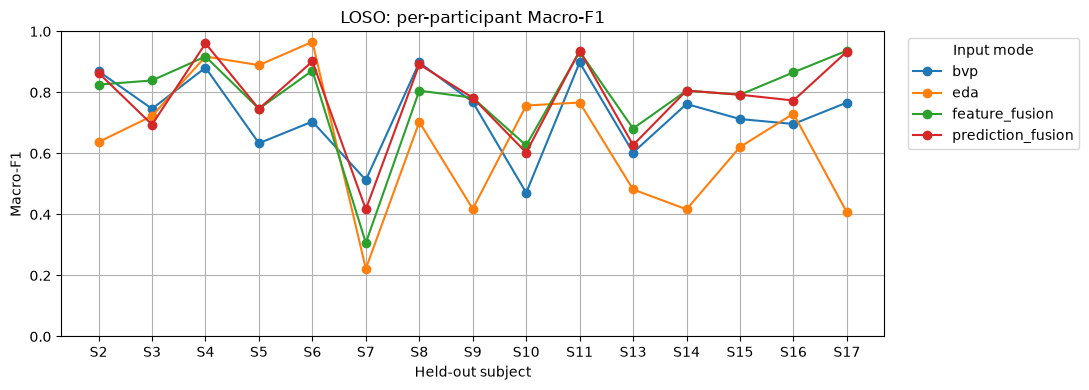

,model_family,subject,fusion_mode,reference_mode,delta_macro_f1
0,baseline_lr,S2,feature_fusion,eda,0.188034
1,baseline_lr,S2,feature_fusion,bvp,-0.043651
2,baseline_lr,S2,prediction_fusion,eda,0.226274
3,baseline_lr,S2,prediction_fusion,bvp,-0.005411
4,baseline_lr,S3,feature_fusion,eda,0.116335
5,baseline_lr,S3,feature_fusion,bvp,0.092871
6,baseline_lr,S3,prediction_fusion,eda,-0.028245
7,baseline_lr,S3,prediction_fusion,bvp,-0.051709


In [5]:
participant_metrics = pd.read_csv(results_dir / 'participant_metrics.csv')
scores = participant_metrics.pivot(index='subject', columns='input_mode', values='macro_f1')
subject_order = sorted(scores.index, key=lambda s: int(str(s)[1:]))
scores = scores.loc[subject_order]
ax = scores.plot(marker='o', figsize=(11, 4), ylim=(0, 1), grid=True)
ax.set(xlabel='Held-out subject', ylabel='Macro-F1', title='LOSO: per-participant Macro-F1')
ax.set_xticks(range(len(scores)), scores.index)
ax.legend(title='Input mode', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
ax.figure.savefig(results_dir / 'participant_macro_f1.png', dpi=160, bbox_inches='tight')
plt.show()
display(pd.read_csv(results_dir / 'fusion_deltas.csv').head(8))


## 5. 조건별 오류와 실행 검수

Baseline·Amusement에서는 오탐, Stress에서는 누락을 확인합니다. 오류율에는 분자와 분모가 필요하며 분모가 없으면 비율은 결측입니다. CSV의 예측으로 점수와 오류를 재계산할 수 있어야 합니다.

전체 513구간 기준으로 예측은 2,052행, 참가자별 점수는 60행입니다. 아래 확인은 입력 특징의 실제 참가자·구간 수에 맞춰 pilot에도 적용됩니다. 별도 명령 `python -m wesad_starter verify --output-dir results/baseline`으로 저장 결과의 일관성도 확인하세요.

In [6]:
predictions = pd.read_csv(results_dir / 'predictions.csv')
assert len(predictions) == 4 * len(features)
assert len(participant_metrics) == 4 * features.subject.nunique()
assert not features.duplicated(['subject', 'window_id']).any()
display(pd.read_csv(results_dir / 'condition_errors.csv').head(12))
print('기본 행 수와 구간 ID 확인 완료')


,model_family,input_mode,subject,original_condition,condition_name,error_type,numerator,denominator,error_rate
0,baseline_lr,eda,S2,1,baseline,false_positive,0,18,0.000000
1,baseline_lr,eda,S2,2,stress,false_negative,7,10,0.700000
2,baseline_lr,eda,S2,3,amusement,false_positive,1,5,0.200000
3,baseline_lr,bvp,S2,1,baseline,false_positive,2,18,0.111111
4,baseline_lr,bvp,S2,2,stress,false_negative,0,10,0.000000
5,baseline_lr,bvp,S2,3,amusement,false_positive,2,5,0.400000
6,baseline_lr,feature_fusion,S2,1,baseline,false_positive,2,18,0.111111
7,baseline_lr,feature_fusion,S2,2,stress,false_negative,2,10,0.200000
8,baseline_lr,feature_fusion,S2,3,amusement,false_positive,1,5,0.200000
9,baseline_lr,prediction_fusion,S2,1,baseline,false_positive,1,18,0.055556


기본 행 수와 구간 ID 확인 완료


## 6. 학생의 연구 실험으로 확장

- **Advanced Model:** 개선 아이디어를 제안·구현하고 같은 참가자 분할·구간에서 네 조건을 비교합니다.
- **RQ1:** 참가자별 이득/악화와 EDA·BVP 오류 중복의 관계를 해석합니다.
- **RQ2:** BVP 잡음 두 수준, 적용 시점과 재학습 여부를 사전에 정합니다.
- **RQ3:** 외부 학습 참가자 안의 참가자 단위 검증으로 융합 가중치를 고릅니다. 내부 전처리도 내부 학습 참가자에게만 맞춥니다.
- **RQ4:** 서로 다른 예측을 내는 동일 신호 두 모델 앙상블과 EDA+BVP 융합을 모델 수·학습 예산을 통제하여 비교합니다. 동일한 LR을 복제하는 것으로 대체하지 않습니다.

유한값 검사 통과는 움직임 잡음이 없다는 뜻이 아닙니다. 구간 수를 참가자 수로 취급하지 말고, 15명과 겹치는 LOSO 학습 집합의 한계를 설명하세요. 융합 향상만으로 생리적 상호 보완성이나 인과 관계가 입증되지는 않습니다.
